In [20]:
import cv2
import glob
import matplotlib.pyplot as plt

from model import Model

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [23]:
model = Model(
    "../leg_position_detectors/yolov8/run_results/model_2_5m_params/320/weights/best_saved_model/best_full_integer_quant.tflite",
    "../leg_position_detectors/yolov8/detection_head/2_5m_model/320/saved_model/head_320_float32.tflite"
)

In [25]:
tst_img_paths = sorted(glob.glob("/home/kyamkovyi/projects/gap9/datasets/position_db_pose/images/test/*.jpg"))
len(tst_img_paths)


490

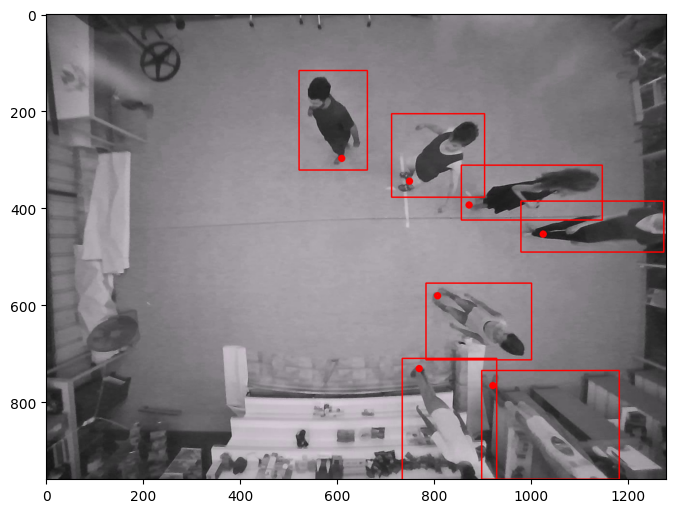

In [26]:
img = cv2.cvtColor(cv2.imread(tst_img_paths[10]), cv2.COLOR_BGR2RGB)

detections = model.predict(img)

for box in detections:
    cv2.rectangle(img, (box[:2] / RATIO).astype(int), ((box[:2].astype(int) + box[2:4]) / RATIO).astype(int) , (255, 0, 0), 2)

for p in detections:
    cv2.circle(img, (p[-2:] // RATIO).astype(int), 4, (255, 0, 0), 5)

plt.figure(figsize=(8, 8))
plt.imshow(img)